In [1]:
# Cell 1: import library
import os 
import hashlib
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image, ImageFile
import imagehash
from tqdm.auto import tqdm
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
# Cell 2: load dataset & setup
# Allow PIL to load truncated images so check them
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Global Config
SEED = 42
RAW_DATA_DIR = Path("../data/raw/data1a")
OUT_DIR = Path("../reports/audit")  # save the CSVs 
OUT_DIR.mkdir(parents=True, exist_ok= True)


# Label Mapping
LABEL_MAP = {
    "00-damage": "damaged",
    "01-whole": "whole"
}

print(f"Raw data directory: {RAW_DATA_DIR.resolve()}")
print(f"Output directory: {OUT_DIR.resolve()}")

Raw data directory: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\data\raw\data1a
Output directory: C:\Users\ASUS\Desktop\AI_Projects\InsureClaim-Vision\reports\audit


In [3]:
# Cell 3: Build Master File Inventory
# Find all image files recursively
image_extensions = {".jpg", ".jpeg", ".bmp", ".webp"}
inventory_data = []

# check the directory
for root, dirs, files in os.walk(RAW_DATA_DIR):
    for file in files:
        ext = Path(file).suffix.lower()
        if ext in image_extensions:
            full_path = Path(root) / file
            # Extract split (training / validation) and raw class (00-damage/01-whole)
            parts = full_path.parts
            split_raw = parts[-3]     # training or validation
            class_raw = parts[-2]     # 00-damage or 01-whole

            # Map to standard names
            split = "train" if "training" in split_raw.lower() else "valid"
            label = LABEL_MAP.get(class_raw, "unknown")

            inventory_data.append({
                "image_path": str(full_path.relative_to(RAW_DATA_DIR)),
                "filename": file,
                "split": split,
                "label": label,
                "raw_class": class_raw
            })

df_inv = pd.DataFrame(inventory_data)
print(f"Total images found: {len(df_inv)}")
print("\nCounts by split and label:")
print(df_inv.groupby(["split", "label"]).size())

# check for unmapped labels
if "unknown" in df_inv["label"].values:
    print("\nFound unmapped classes !")
    print(df_inv[df_inv["label"] == "unknown"]["raw_class"].unique())
else:
    print("\nAll folder names successfully mapped to labels.")

Total images found: 2300

Counts by split and label:
split  label  
train  damaged    920
       whole      920
valid  damaged    230
       whole      230
dtype: int64

All folder names successfully mapped to labels.


In [4]:
# Cell 4: File Extensions & Corrupt Image Check
# Check extensions
ext_counts = df_inv["filename"].apply(lambda x: Path(x).suffix.lower()).value_counts()
print("File extensions found:")
print(ext_counts)

# Check for corruption and get basic metadata
valid_images = []
corrupt_images = []

for idx, row in tqdm(df_inv.iterrows(), total=len(df_inv)):
    full_path = RAW_DATA_DIR / row["image_path"]
    try:
        with Image.open(full_path) as img:
            img.verify()    # checks for corruption without loading full image

        # Re-open to get properties (verify() close the file)
        with Image.open(full_path) as img:
            width, height = img.size
            mode = img.mode

        # if successful, append to valid
        row_dict = row.to_dict()
        row_dict.update({"width": width, "height": height, "color_mode": mode, "is_corrupted": False})
        valid_images.append(row_dict)

    except Exception as e:
        row_dict = row.to_dict()
        row_dict.update({"error": str(e), "is_corrupted": True})
        corrupt_images.append(row_dict)


df_valid = pd.DataFrame(valid_images)
df_corrupt = pd.DataFrame(corrupt_images)

print(f"\n Valid image: {len(df_valid)}")
print(f"Corrupted images: {len(df_corrupt)}")

if len(df_corrupt) > 0:
    print("\nCorrupted files:")
    print(df_corrupt[["image_path", "error"]])
    df_corrupt.to_csv(OUT_DIR / "corrupted_images.csv", index=False)


File extensions found:
filename
.jpeg    1309
.jpg      991
Name: count, dtype: int64


  0%|          | 0/2300 [00:00<?, ?it/s]


 Valid image: 2300
Corrupted images: 0


In [5]:
# Cell 5: Image Dimensions, Color Modes, & File Sizes
# Add file size
df_valid["file_size"] = df_valid["image_path"].apply(lambda x: (RAW_DATA_DIR / x).stat().st_size)
df_valid["aspect_ratio"] = df_valid["width"] / df_valid["height"]

print("--- Color Modes by Class ----")
print(pd.crosstab(df_valid["label"], df_valid["color_mode"]))

print("--- Image Dimensions Summary ---")
print(df_valid.groupby("label")[["width", "height", "aspect_ratio", "file_size"]].describe().T)

# Flag unusual properties
grayscale = df_valid[df_valid["color_mode"].isin(["L", "1"])]
rgba = df_valid[df_valid["color_mode"] == "RGBA"]
tiny = df_valid[(df_valid["width"] < 100) | (df_valid["height"] < 100)]
extreme_ratio = df_valid[(df_valid["aspect_ratio"] < 0.5) | (df_valid["aspect_ratio"] > 2.0)]

print(f"\nUnusual properties found:")
print(f"Grayscale: {len(grayscale)} images")
print(f"RGBA: {len(rgba)} images")
print(f"Very small (<100px): {len(tiny)} images")
print(f"Extreme aspect ratio (<0.5 or >2.0): {len(extreme_ratio)} images")

--- Color Modes by Class ----
color_mode  L   RGB
label              
damaged     0  1150
whole       1  1149
--- Image Dimensions Summary ---
label                    damaged         whole
width        count   1150.000000  1.150000e+03
             mean     266.192174  6.308565e+02
             std       26.480144  4.372867e+02
             min      165.000000  1.120000e+02
             25%      259.000000  3.000000e+02
             50%      260.000000  5.890000e+02
             75%      275.000000  7.717500e+02
             max      414.000000  4.912000e+03
height       count   1150.000000  1.150000e+03
             mean     191.174783  4.346930e+02
             std       21.633144  3.026208e+02
             min      122.000000  7.400000e+01
             25%      183.000000  1.940000e+02
             50%      194.000000  3.745000e+02
             75%      194.000000  4.920000e+02
             max      306.000000  3.264000e+03
aspect_ratio count   1150.000000  1.150000e+03
           

In [6]:
# Cell 6: Exact Duplicates (SHA-256)
def get_sha256(filepath):
    hash_sha256 = hashlib.sha256()
    with open(filepath, "rb") as f:
        # Read in chunks to avoid memory issues with large files
        for chunk in iter(lambda: f.read(4096), b""):
            hash_sha256.update(chunk)
    return hash_sha256.hexdigest()

print("Claculating SHA-256 hashes...")
tqdm.pandas(desc="Hashing")
df_valid["sha256"] = df_valid["image_path"].progress_apply(lambda x: get_sha256(RAW_DATA_DIR / x))

# Find duplicates
sha_duplicates = df_valid[df_valid.duplicated(subset=["sha256"], keep=False)].sort_values("sha256")

print(f"\nExact duplicate groups found: {sha_duplicates['sha256'].nunique()}")
print(f"Total images involved in exact duplicates: {len(sha_duplicates)}")

if len(sha_duplicates) > 0:
    print("\nTop duplicate groups:")
    print(sha_duplicates.groupby("sha256").size().sort_values(ascending = False).head(10))
    sha_duplicates.to_csv(OUT_DIR / "exact_duplicates.csv", index = False)

Claculating SHA-256 hashes...


Hashing:   0%|          | 0/2300 [00:00<?, ?it/s]


Exact duplicate groups found: 13
Total images involved in exact duplicates: 26

Top duplicate groups:
sha256
224fb2be739f2e077bf3a1bf2a30b61b7dc7dd2408714c2426472bbe3179045b    2
298db71585f78b044322bf427277896481f892cbc9d185dd889d08520ad8d4e5    2
2c0e48d5e62e16cfe4781922263913a174e474a77cc8e9e9662d698e435dddb0    2
34c1fe20795b05f46c6d9e888d7734ac8609edfd3bd690246ede521f136b837d    2
42729fb0fef7230f6c1f5727ff3c0e18c330cd5e64f3771d9037ad102d88603e    2
4b9f1bc35ba42b49d134027956bbe5fdd1ddca9ed6ea9ece954b6a3a5edc1296    2
5db1d1820e0cecd177ffc0b09bf4d13edeb74a4c374c2b14b28b5281a5fc789b    2
6e76b4396eeb4c474771bca780a9e85f859841c973678f21346f174d81e8d909    2
6f3372296185251320a5a020b53e78855d77ec15bfd013aa43cc7858fa045eaa    2
9448b3ac0a59374e2b8405ae3a4734434b722a6c7e6b58f71cae3b2b91d06871    2
dtype: int64


Calculating Perceptual Hashes (pHash)...


Hashing:   0%|          | 0/2300 [00:00<?, ?it/s]

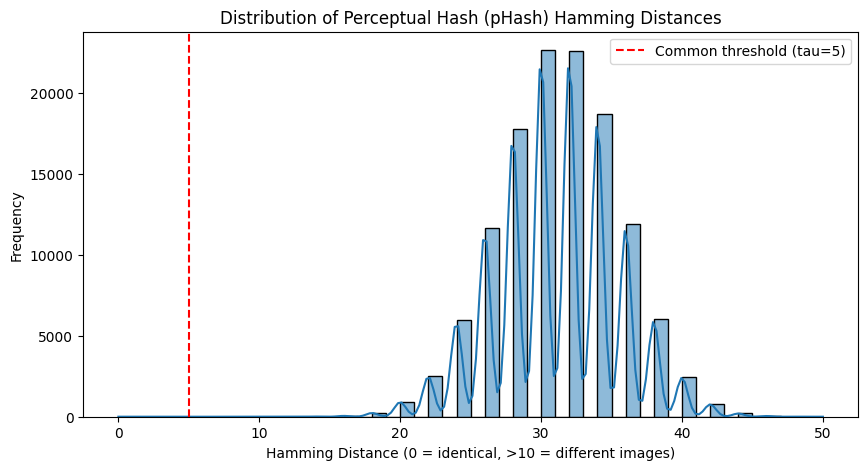

Median distance in sample: 32.0
Review the plot above. We usually pick a threshold where the low-distance peak ends.


In [7]:
# Cell 7: Perceptual Hashing & Distance Calibration
def get_phash(filepath):
    try:
        with Image.open(filepath) as img:
            return str(imagehash.phash(img))
    except Exception:
        return None

print("Calculating Perceptual Hashes (pHash)...")
df_valid["phash"] = df_valid["image_path"].progress_apply(lambda x: get_phash(RAW_DATA_DIR / x))

# Compare every image to every other image to see the distance distribution.
# To save time on large datasets, we'll sample a subset for the histogram.
sample_size = min(500, len(df_valid))
df_sample = df_valid.sample(n=sample_size, random_state=SEED)

distances = []
phash_objs = [imagehash.hex_to_hash(h) for h in df_sample["phash"] if h is not None]

# Calculate pariwise distances for the sample
for i in range(len(phash_objs)):
    for j in range(i + 1, len(phash_objs)):
        distances.append(phash_objs[i] - phash_objs[j])

# Plot the distributions of distances 
plt.figure(figsize=(10, 5))
sns.histplot(distances, bins= 50, kde=True)
plt.title("Distribution of Perceptual Hash (pHash) Hamming Distances")
plt.xlabel("Hamming Distance (0 = identical, >10 = different images)")
plt.ylabel("Frequency")
plt.axvline(x=5, color='r', linestyle='--', label='Common threshold (tau=5)')
plt.legend()
plt.show()

print(f"Median distance in sample: {np.median(distances)}")
print("Review the plot above. We usually pick a threshold where the low-distance peak ends.")

In [8]:
# Cell 8: Build Near-Duplicate Groups
# Threshold based on Calibration plot above
# Distance <= 5 means highly likely to be the same underlying image.
PHASH_THRESHOLD = 5

print(f"Grouping images with pHash distance <= {PHASH_THRESHOLD}...")
# Convert strings back to hash objects for fast comparision
df_valid["phash_obj"] = df_valid["phash"].apply(lambda x: imagehash.hex_to_hash(x) if x else None)

# To find connected components efficiently, use a sample union-find (disjoing set) algorithm.
parent = {i: i for i in df_valid.index}
def find(i):
    if parent[i] == i:
        return i
    parent[i] = find(parent[i])
    return parent[i]

def union(i, j):
    root_i = find(i)
    root_j = find(j)
    if root_i != root_j:
        parent[root_i] = root_j

# Compare all paris (O(N^2) but manageable for ~2k-5k images)
# For larger datasets, use BK-trees or locality-sensitive hashing.
phash_list = df_valid["phash_obj"].tolist()
indices = df_valid.index.tolist()

for i_idx in tqdm(range(len(phash_list)), desc="Grouping"):
    if phash_list[i_idx] is None:
        continue
    for j_idx in range(i_idx + 1, len(phash_list)):
        if phash_list[j_idx] is None:
            continue
        if phash_list[i_idx] - phash_list[j_idx] <= PHASH_THRESHOLD:
            union(indices[i_idx], indices[j_idx])

# Assign group IDs
df_valid["group_id"] = [find(i) for i in df_valid.index]

# Check how many multi-image groups we have
group_sizes = df_valid.groupby("group_id").size()
multi_groups = group_sizes[group_sizes > 1]
print(f"\nTotal groups: {len(group_sizes)}")
print(f"Groups with >1 image (near-duplicates): {len(multi_groups)}")
print(f"Total images in these groups: {multi_groups.sum()}")

if len(multi_groups) > 0:
    # Save these groups so we can inspect them later
    df_groups = df_valid[df_valid["group_id"].isin(multi_groups.index)]
    df_groups[["image_path", "split", "label", "group_id", "phash"]].sort_values("group_id").to_csv(OUT_DIR / "near_duplicate_groups.csv", index=False)
    print("\nSaved near-duplicate groups to reports/audit/near_duplicate_groups.csv")

Grouping images with pHash distance <= 5...


Grouping:   0%|          | 0/2300 [00:00<?, ?it/s]


Total groups: 2278
Groups with >1 image (near-duplicates): 22
Total images in these groups: 44

Saved near-duplicate groups to reports/audit/near_duplicate_groups.csv


In [9]:
# Cell 9: Cross-Split Leakage Check
print("Checking for data leakage...")

# 1. Exact duplicate across splits 
exact_leak = df_valid.groupby("sha256")["split"].nunique()
exact_leak_groups = exact_leak[exact_leak > 1]
print(f"Exact duplicate groups spanning both train and valid: {len(exact_leak_groups)}")

# 2. Near-duplicate groups across splits
group_leak = df_valid.groupby("group_id")["split"].nunique()
group_leak_ids = group_leak[group_leak > 1]
print(f"Near-duplicate groups spanning both train and valid: {len(group_leak_ids)}")

if len(group_leak_ids) > 0:
    print("\nLeakage detected! Here are the affected groups:")
    leaked_images = df_valid[df_valid["group_id"].isin(group_leak_ids.index)]
    print(leaked_images[["image_path", "split", "label", "group_id"]].sort_values("group_id"))
    print("\nWe will need to address this in Notebook 03 (Preprocessing) by moving these groups to one split.")
else:
    print("\nNo cross-split leakage detected for the chosen threshold.")

Checking for data leakage...
Exact duplicate groups spanning both train and valid: 3
Near-duplicate groups spanning both train and valid: 6

Leakage detected! Here are the affected groups:
                          image_path  split    label  group_id
554     training\00-damage\0555.JPEG  train  damaged      1860
1860  validation\00-damage\0021.JPEG  valid  damaged      1860
1863  validation\00-damage\0024.JPEG  valid  damaged      1863
138     training\00-damage\0139.JPEG  train  damaged      1863
18      training\00-damage\0019.JPEG  train  damaged      1864
1864  validation\00-damage\0025.jpeg  valid  damaged      1864
2044  validation\00-damage\0205.JPEG  valid  damaged      2044
133     training\00-damage\0134.JPEG  train  damaged      2044
2046  validation\00-damage\0207.JPEG  valid  damaged      2046
656     training\00-damage\0657.JPEG  train  damaged      2046
1768     training\01-whole\0849.JPEG  train    whole      2272
2272   validation\01-whole\0203.JPEG  valid    whole   

In [11]:
# Cell 10: Labeling & Dataset Limitations Check
print("--- Dataset Scope Check ---")
print(f"Total unique classes found: {df_valid['label'].nunique()}")
print(f"Classes: {df_valid['label'].unique().tolist()}")


# Are there any annotation files (XML, JSON, TXT) in the raw dict
annotation_files = []
for root, dirs, files in os.walk(RAW_DATA_DIR):
    for file in files:
        if file.endswith((".xml", ".json", ".txt", ".csv")):
            annotation_files.append(file)

print(f"\nAnnotation files found: {len(annotation_files)}")
if len(annotation_files) == 0:
    print("Dataset contains ONLY image-level labels (no bounding boxes, maks, or severity).")

print("\n--- Test Set check ---")
print(f"Splits availabel: {df_valid['split'].unique().tolist()}")
print("No test set provided in the dataset. We must create one in Notebook 03.")

--- Dataset Scope Check ---
Total unique classes found: 2
Classes: ['damaged', 'whole']

Annotation files found: 0
Dataset contains ONLY image-level labels (no bounding boxes, maks, or severity).

--- Test Set check ---
Splits availabel: ['train', 'valid']
No test set provided in the dataset. We must create one in Notebook 03.


In [12]:
# Cell 11: Save Mastery Inventory & Symmary
print("Saving master dataset inventory...")

# Select and reorder final columns
final_columns = [
    "image_path", "filename", "split", "label", "width", "height",
    "aspect_ratio", "color_mode", "file_size", "sha256", "phash",
    "is_corrupted", "group_id"
]

df_inventory = df_valid[final_columns]
df_inventory.to_csv(OUT_DIR / "dataset_inventory.csv", index=False)
print(f"Saved dataset_inventory.csv with {len(df_inventory)} rows.")

# Create a high-level summary CSV
summary_data = {
    "total_images": len(df_inventory),
    "train_images": len(df_inventory[df_inventory["split"] == "train"]),
    "valid_images": len(df_inventory[df_inventory["split"] == "valid"]),
    "damaged_images": len(df_inventory[df_inventory["label"] == "damaged"]),
    "whole_images": len(df_inventory[df_inventory["label"] == "whole"]),
    "corrupted_images": len(df_corrupt),
    "exact_duplicate_groups": df_inventory[df_inventory.duplicated("sha256", keep=False)]["sha256"].nunique(),
    "near_duplicate_groups": len(multi_groups),
    "cross_split_leaks": len(group_leak_ids)
}
df_summary = pd.DataFrame([summary_data])
df_summary.to_csv(OUT_DIR / "dataset_summary.csv", index=False)
print("Saved dataset_summary.csv")

print("\nAudit complete! Please review the CSVs in reports/audit/")

Saving master dataset inventory...
Saved dataset_inventory.csv with 2300 rows.
Saved dataset_summary.csv

Audit complete! Please review the CSVs in reports/audit/


## Dataset Audit Summary

**1. Dataset Overview**
- Total Images: 2300
- Train Set: 1840 images (920 damaged, 920 whole)
- Validation Set: 460 images (230 damaged, 230 whole)
- Class balance is perfectly 50/50.
- No test set exists. We will create one in Notebook 03.

**2. Data Integrity**
- All images are valid (0 corrupted files).
- File formats: 1309 `.jpeg`, 991 `.jpg`.
- Unusual properties: 1 Grayscale image, 12 very small images (<100px), 57 extreme aspect ratios.

**3. Duplication & Leakage (Critical)**
- Exact duplicates: 13 groups (26 images).
- Near-duplicates (pHash <= 5): 22 groups (44 images).
- **DATA LEAKAGE DETECTED:** 6 near-duplicate groups span across both train and validation splits. 
  - 5 damaged groups, 1 whole group.
  - Action: Resolve in Notebook 03 by moving these groups entirely into one split.

**4. Shortcut Feature Risk (Critical)**
- **Image Dimensions:** Damaged images have a mean width of ~266px. Whole images have a mean width of ~631px. 
- **Risk:** The model may learn to classify based on image resolution/aspect ratio (a shortcut) rather than actual vehicle damage. 
- Action: Investigate visually in Notebook 02, and address in Notebook 03 (e.g., resizing strategy).

**5. Label Scope**
- Confirmed: Only image-level labels (binary: damaged vs whole) exist.
- No bounding boxes, masks, or severity labels are present. 